# Artificial Intelligence Lab - LAB 03
## Experiment 3: Graph Representations & Uninformed Searches (BFS, DFS, Dijkstra)
### Objectives:
1. Translate visual graph into Python data structures:
   - `adj_list` (Dictionary)
   - `adj_matrix` (2D nested list with `math.inf` sentinel)
2. Explain why 0 is wrong as a sentinel for 'no edge'.
3. Plot graphs for both representations.
4. Implement BFS, DFS, and Dijkstra from scratch returning `(path, total_cost, visit_order)`.
5. Display comparison table and highlight search paths in red.

### 1. Data Structures & Mathematical Rationale
**Why 0 is wrong for 'no edge'**:
In weighted graphs, 0 represents a valid edge of zero cost (free transition). Using 0 for absent edges leads algorithms like Dijkstra to consider disconnected vertices as freely accessible, corrupting shortest paths. We must use `math.inf`.

In [1]:
import math
import heapq
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx

nodes = ['A', 'B', 'C', 'D', 'E', 'F']
node_to_idx = {n: i for i, n in enumerate(nodes)}

# 1. Adjacency List (Dictionary of neighbor, weight tuples)
adj_list = {
    'A': [('B', 4), ('C', 4)],
    'B': [('A', 4), ('C', 2), ('E', 1)],
    'C': [('A', 4), ('B', 2), ('D', 1)],
    'D': [('C', 1), ('F', 2)],
    'E': [('B', 1), ('F', 4)],
    'F': [('D', 2), ('E', 4)]
}

# 2. Adjacency Matrix (with math.inf sentinel)
adj_matrix = [
    #  A         B         C         D         E         F
    [0,        4,        4,        math.inf, math.inf, math.inf],  # A
    [4,        0,        2,        math.inf, 1,        math.inf],  # B
    [4,        2,        0,        1,        math.inf, math.inf],  # C
    [math.inf, math.inf, 1,        0,        math.inf, 2],         # D
    [math.inf, 1,        math.inf, math.inf, 0,        4],         # E
    [math.inf, math.inf, math.inf, 2,        4,        0]          # F
]

graph_pos = {
    'A': (0.0, 1.0),
    'B': (1.0, 1.6),
    'C': (1.0, 0.4),
    'D': (2.0, 2.0),
    'E': (2.0, 0.5),
    'F': (2.8, 1.3)
}

### 2. Plotting Graphs from Both Representations

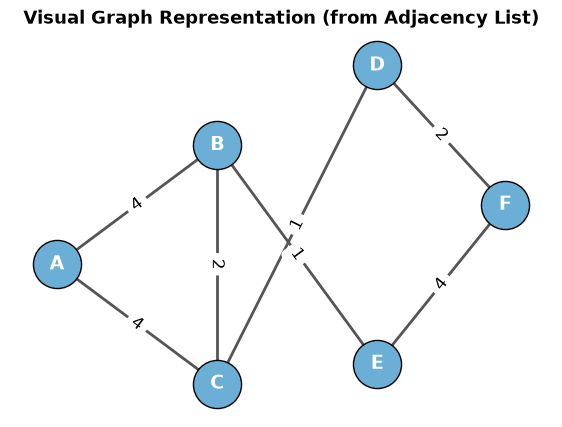

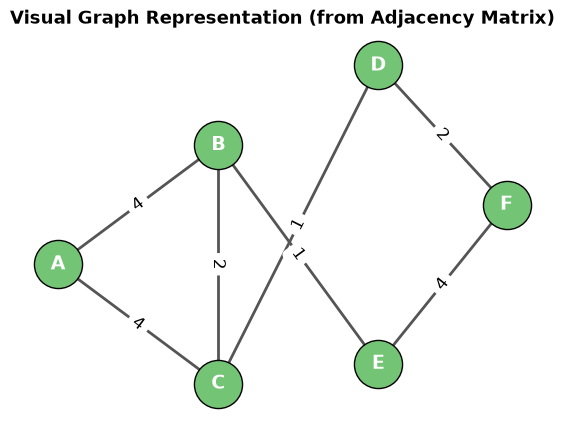

In [2]:
def plot_graph_from_adj_list():
    G = nx.Graph()
    for u, neighbors in adj_list.items():
        for v, w in neighbors:
            G.add_edge(u, v, weight=w)

    plt.figure(figsize=(7, 5))
    nx.draw_networkx_nodes(G, graph_pos, node_color='#6baed6', node_size=1200, edgecolors='black')
    nx.draw_networkx_labels(G, graph_pos, font_size=14, font_weight='bold', font_color='white')
    nx.draw_networkx_edges(G, graph_pos, width=2, edge_color='#555555')
    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, graph_pos, edge_labels=edge_labels, font_size=12)
    plt.title("Visual Graph Representation (from Adjacency List)", fontsize=13, fontweight='bold')
    plt.axis('off')
    plt.show()

def plot_graph_from_adj_matrix():
    G = nx.Graph()
    n = len(nodes)
    for i in range(n):
        for j in range(i + 1, n):
            w = adj_matrix[i][j]
            if w != math.inf and w > 0:
                G.add_edge(nodes[i], nodes[j], weight=int(w))

    plt.figure(figsize=(7, 5))
    nx.draw_networkx_nodes(G, graph_pos, node_color='#74c476', node_size=1200, edgecolors='black')
    nx.draw_networkx_labels(G, graph_pos, font_size=14, font_weight='bold', font_color='white')
    nx.draw_networkx_edges(G, graph_pos, width=2, edge_color='#555555')
    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, graph_pos, edge_labels=edge_labels, font_size=12)
    plt.title("Visual Graph Representation (from Adjacency Matrix)", fontsize=13, fontweight='bold')
    plt.axis('off')
    plt.show()

plot_graph_from_adj_list()
plot_graph_from_adj_matrix()

### 3. Implementation of BFS, DFS, and Dijkstra's Algorithms

In [3]:
def get_path_cost(adj, path):
    cost = 0
    for u, v in zip(path[:-1], path[1:]):
        for nbr, w in adj[u]:
            if nbr == v:
                cost += w
                break
    return cost

def bfs_path(adj, start='A', goal='F'):
    queue = deque([[start]])
    visited = {start}
    visit_order = [start]

    while queue:
        path = queue.popleft()
        node = path[-1]
        if node == goal:
            return path, get_path_cost(adj, path), visit_order

        for nbr, _ in sorted(adj[node], key=lambda x: x[0]):
            if nbr not in visited:
                visited.add(nbr)
                visit_order.append(nbr)
                queue.append(path + [nbr])

    return None, 0, visit_order

def dfs_path(adj, start='A', goal='F'):
    stack = [[start]]
    visited = set()
    visit_order = []

    while stack:
        path = stack.pop()
        node = path[-1]
        if node not in visited:
            visited.add(node)
            visit_order.append(node)
            if node == goal:
                return path, get_path_cost(adj, path), visit_order

            for nbr, _ in sorted(adj[node], key=lambda x: x[0], reverse=True):
                if nbr not in visited:
                    stack.append(path + [nbr])

    return None, 0, visit_order

def dijkstra_path(adj, start='A', goal='F'):
    dist = {n: math.inf for n in adj}
    parent = {n: None for n in adj}
    dist[start] = 0
    pq = [(0, start)]
    visit_order = []
    visited = set()

    while pq:
        d, u = heapq.heappop(pq)
        if u in visited:
            continue
        visited.add(u)
        visit_order.append(u)
        if u == goal:
            break

        for v, weight in sorted(adj[u], key=lambda x: x[0]):
            if dist[u] + weight < dist[v]:
                dist[v] = dist[u] + weight
                parent[v] = u
                heapq.heappush(pq, (dist[v], v))

    path = []
    curr = goal
    while curr is not None:
        path.append(curr)
        curr = parent[curr]
    path.reverse()

    return path, dist[goal], visit_order

### 4. Running Searches and Comparing Results

In [4]:
bfs_res = bfs_path(adj_list, 'A', 'F')
dfs_res = dfs_path(adj_list, 'A', 'F')
dijkstra_res = dijkstra_path(adj_list, 'A', 'F')

results = [
    ("Breadth-First Search (BFS)", bfs_res),
    ("Depth-First Search (DFS)", dfs_res),
    ("Dijkstra's Algorithm", dijkstra_res)
]

print("-" * 75)
print(f"{'Algorithm Name':<30} | {'Path':<20} | {'Edge Count':<10} | {'Total Cost':<10}")
print("-" * 75)
for name, (path, cost, order) in results:
    path_str = " -> ".join(path)
    edge_count = len(path) - 1
    print(f"{name:<30} | {path_str:<20} | {edge_count:<10} | {cost:<10}")
print("-" * 75)

---------------------------------------------------------------------------
Algorithm Name                 | Path                 | Edge Count | Total Cost
---------------------------------------------------------------------------
Breadth-First Search (BFS)     | A -> B -> E -> F     | 3          | 9         
Depth-First Search (DFS)       | A -> B -> C -> D -> F | 4          | 9         
Dijkstra's Algorithm           | A -> C -> D -> F     | 3          | 7         
---------------------------------------------------------------------------


### 5. Visualizing the Discovered Paths in Red

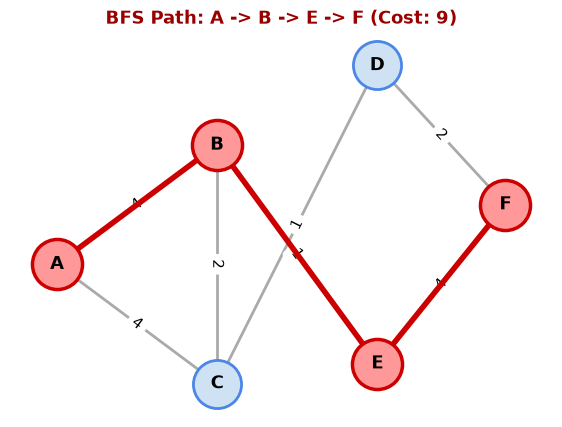

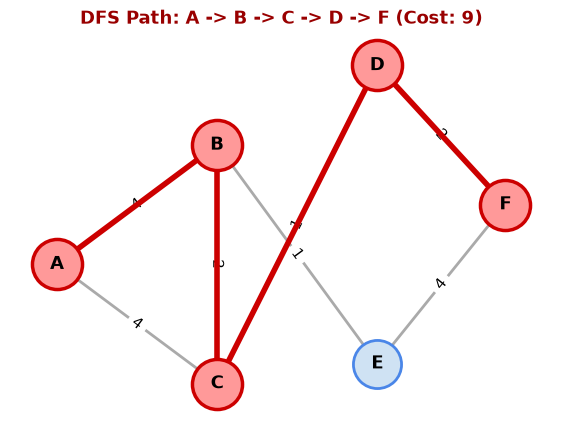

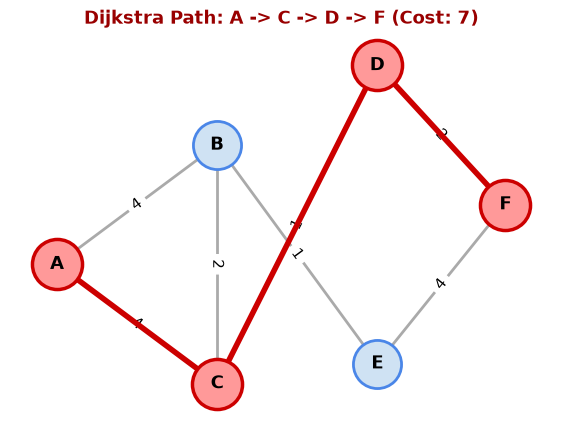

In [5]:
def visualize_search_path(adj, path, title):
    G = nx.Graph()
    for u, neighbors in adj.items():
        for v, w in neighbors:
            G.add_edge(u, v, weight=w)

    path_edges = list(zip(path[:-1], path[1:]))

    plt.figure(figsize=(7, 5))
    nx.draw_networkx_nodes(G, graph_pos, node_color='#cfe2f3', node_size=1200, edgecolors='#4a86e8', linewidths=2)
    nx.draw_networkx_labels(G, graph_pos, font_size=13, font_weight='bold')
    nx.draw_networkx_edges(G, graph_pos, width=2, edge_color='#aaaaaa')
    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, graph_pos, edge_labels=edge_labels, font_size=11)

    # Highlight path in red
    nx.draw_networkx_nodes(G, graph_pos, nodelist=path, node_color='#ff9999', node_size=1300, edgecolors='#cc0000', linewidths=2.5)
    nx.draw_networkx_edges(G, graph_pos, edgelist=path_edges, width=4, edge_color='#cc0000')

    plt.title(title, fontsize=13, fontweight='bold', color='#990000')
    plt.axis('off')
    plt.show()

visualize_search_path(adj_list, bfs_res[0], f"BFS Path: {' -> '.join(bfs_res[0])} (Cost: {bfs_res[1]})")
visualize_search_path(adj_list, dfs_res[0], f"DFS Path: {' -> '.join(dfs_res[0])} (Cost: {dfs_res[1]})")
visualize_search_path(adj_list, dijkstra_res[0], f"Dijkstra Path: {' -> '.join(dijkstra_res[0])} (Cost: {dijkstra_res[1]})")